# Part 3  Descriptive Statistics and Exploratory Data Analysis

In this part, I explored Melt Gelato’s sales data to understand how customer demand changes throughout the year.

I focused on daily revenue, monthly trends, weekdays, trading hours and product performance. The aim was to identify the busiest periods and the products contributing most to sales, so the findings could support inventory and staffing decisions.


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display

HERE = Path.cwd()
ROOT = HERE.parent if HERE.name == "notebooks" else HERE
RAW_DIR = ROOT / "data" / "raw"
PROCESSED_DIR = ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)


In [5]:

df = pd.read_csv(
    PROCESSED_DIR / "cleaned_sales.csv",
    parse_dates=["sale_date"]
)

print("Cleaned sales dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Cleaned sales dataset loaded successfully!
Dataset shape: (122419, 49)


/var/folders/d_/d5ghnmqx2clg3rh4sk_g_n440000gn/T/ipykernel_71684/2982529649.py:1: DtypeWarning: Columns (8,21,24) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(


,Date,Time,Time Zone,Category,Item,Qty,Price Point Name,SKU,Modifiers Applied,Product Sales,...,Gross Sales_eur,event_type_clean,is_refund,is_payment,is_void,is_exact_duplicate,record_group,gross_check_difference,category_analysis,item_analysis
0,2025-11-30,22:01:14,London,Gelato,Gelato,1.0,2 Scoops,NaN,NaN,€5.50,...,5.5,payment,False,True,False,False,payment,0.0,Gelato,Gelato
1,2025-11-30,22:01:14,London,Toppings,Topping (Voided),10.0,Regular,NaN,NaN,€0.00,...,0.0,payment,False,True,True,False,void label,0.0,Toppings,Topping (Voided)
2,2025-11-30,21:34:18,London,Gelato,Gelato,1.0,2 Scoops,NaN,NaN,€5.50,...,5.5,payment,False,True,False,False,payment,0.0,Gelato,Gelato
3,2025-11-30,21:31:37,London,Milkshakes,Brownie Milkshake,1.0,Regular,NaN,NaN,€6.50,...,6.5,payment,False,True,False,False,payment,0.0,Milkshakes,Brownie Milkshake
4,2025-11-30,21:30:10,London,Milkshakes,Vanilla Milkshake,1.0,Regular,NaN,NaN,€6.00,...,6.0,payment,False,True,False,False,payment,0.0,Milkshakes,Vanilla Milkshake


In [6]:
daily_sales = pd.read_csv(PROCESSED_DIR / "daily_sales.csv", parse_dates=['sale_date'])
print("Loaded daily_sales:", daily_sales.shape)

Loaded daily_sales: (360, 11)


In [7]:
sales_lines = df.loc[df["is_payment"].astype(str).str.lower().eq("true") & ~df["is_void"].astype(str).str.lower().eq("true")].copy()
refund_lines = df.loc[df["is_refund"].astype(str).str.lower().eq("true") & ~df["is_void"].astype(str).str.lower().eq("true")].copy()
print("Payment lines:",len(sales_lines),"Refund lines:",len(refund_lines))

Payment lines: 106156 Refund lines: 844


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

metrics = daily_sales[["payment_gross_eur", "refund_adjusted_gross_eur", "transactions", "units_sold"]]
display(metrics.describe().T.round(2))
print("Coefficient of variation (daily refund-adjusted revenue):",
      round(daily_sales["refund_adjusted_gross_eur"].std() / daily_sales["refund_adjusted_gross_eur"].mean(), 3))
print("Total refund-adjusted gross revenue (€):", round(daily_sales["refund_adjusted_gross_eur"].sum(), 2))
print("Total payment-only units:", int(daily_sales["units_sold"].sum()))

,count,mean,std,min,25%,50%,75%,max
payment_gross_eur,360.0,1522.90,633.28,328.7,1037.88,1431.10,1852.21,4310.8
refund_adjusted_gross_eur,360.0,1507.43,612.09,328.7,1034.78,1418.25,1852.21,4117.9
transactions,360.0,163.59,57.42,46.0,122.75,155.00,193.00,398.0
units_sold,360.0,372.26,158.66,86.0,247.75,345.50,451.50,1033.0


Coefficient of variation (daily refund-adjusted revenue): 0.406
Total refund-adjusted gross revenue (€): 542676.35
Total payment-only units: 134013


### 3.1 Daily sales trend and variability


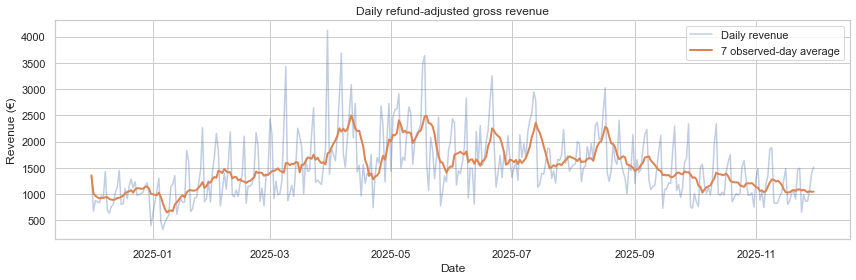

In [9]:
trend = daily_sales.copy()
trend["rolling_7_observed_days"] = trend["refund_adjusted_gross_eur"].rolling(7, min_periods=1).mean()
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(trend["sale_date"], trend["refund_adjusted_gross_eur"], alpha=.35, label="Daily revenue")
ax.plot(trend["sale_date"], trend["rolling_7_observed_days"], linewidth=2, label="7 observed-day average")
ax.set(title="Daily refund-adjusted gross revenue", xlabel="Date", ylabel="Revenue (€)")
ax.legend(); plt.tight_layout(); plt.show()

I started by looking at daily and monthly revenue to understand how sales changed over time.

The analysis showed that May 2025 generated the highest monthly revenue, while January 2025 had the lowest. These differences suggest that demand is not consistent throughout the year, which is important when planning stock and staffing.

### 3.2 Month-level performance (totals and daily averages)


,month_period,revenue_eur,observed_days,transactions,avg_revenue_per_observed_day,month_label
0,2024-12,28651.80,29,3269,987.99,2024-12
1,2025-01,28197.40,28,3275,1007.05,2025-01
2,2025-02,37733.90,28,4053,1347.64,2025-02
3,2025-03,51672.90,31,5920,1666.87,2025-03
4,2025-04,57290.25,30,6463,1909.68,2025-04
5,2025-05,61930.60,31,6453,1997.76,2025-05
6,2025-06,54039.25,30,5565,1801.31,2025-06
7,2025-07,53941.55,31,5637,1740.05,2025-07
8,2025-08,55007.75,31,5655,1774.44,2025-08
9,2025-09,42922.00,30,4736,1430.73,2025-09


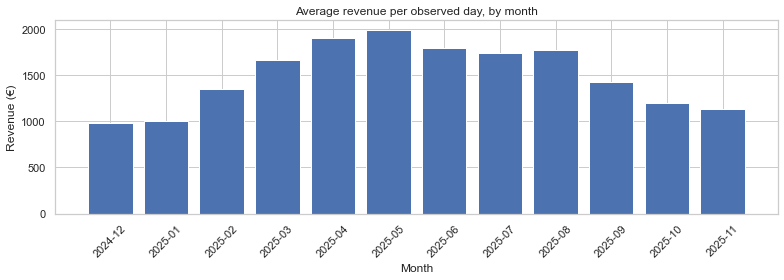

In [10]:
monthly = (daily_sales.assign(month_period=daily_sales["sale_date"].dt.to_period("M"))
    .groupby("month_period", as_index=False)
    .agg(revenue_eur=("refund_adjusted_gross_eur", "sum"),
         observed_days=("sale_date", "size"),
         transactions=("transactions", "sum")))
monthly["avg_revenue_per_observed_day"] = monthly["revenue_eur"] / monthly["observed_days"]
monthly["month_label"] = monthly["month_period"].astype(str)
display(monthly.round(2))
fig, ax = plt.subplots(figsize=(11,4))
ax.bar(monthly["month_label"], monthly["avg_revenue_per_observed_day"])
ax.set(title="Average revenue per observed day, by month", ylabel="Revenue (€)", xlabel="Month")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

### 3.3 Weekday and weekend demand
- A higher weekend average is descriptive evidence
- significance and weather-adjusted effects will be evaluated later. 

,observed_days,total_revenue_eur,avg_daily_revenue_eur,median_daily_revenue_eur
weekday,,,,
Monday,52,63446.45,1220.12,1160.70
Tuesday,52,61119.05,1175.37,1088.97
Wednesday,50,65840.40,1316.81,1188.10
Thursday,50,65679.55,1313.59,1202.18
Friday,51,77560.00,1520.78,1435.20
Saturday,52,96761.45,1860.80,1734.88
Sunday,53,112269.45,2118.29,2118.15


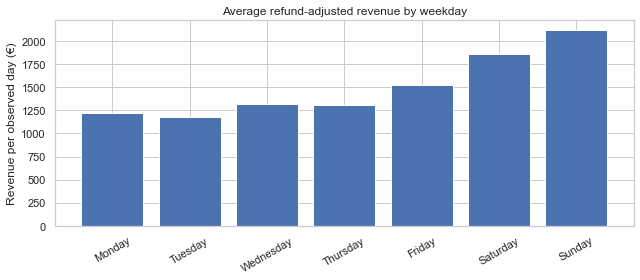

In [11]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_summary = (daily_sales.groupby("weekday")
    .agg(observed_days=("sale_date", "size"), total_revenue_eur=("refund_adjusted_gross_eur", "sum"),
         avg_daily_revenue_eur=("refund_adjusted_gross_eur", "mean"),
         median_daily_revenue_eur=("refund_adjusted_gross_eur", "median"))
    .reindex(order))
display(weekday_summary.round(2))
fig, ax = plt.subplots(figsize=(9,4))
ax.bar(weekday_summary.index, weekday_summary["avg_daily_revenue_eur"])
ax.set(title="Average refund-adjusted revenue by weekday", ylabel="Revenue per observed day (€)")
plt.xticks(rotation=30); plt.tight_layout(); plt.show()

### 3.4 Trading-hour pattern
- Hour is based on the POS `Time` field
- this is **payment-line quantity by hour**, not staffing utilisation or unique customer visits. 

,units,gross_eur
sale_hour,,
0,125.0,481.90
1,26.0,139.60
6,1.0,3.30
7,448.0,1640.25
8,2394.0,8745.75
9,4506.0,16704.25
10,5370.0,20638.70
11,7732.0,29741.95
12,8726.0,35404.35


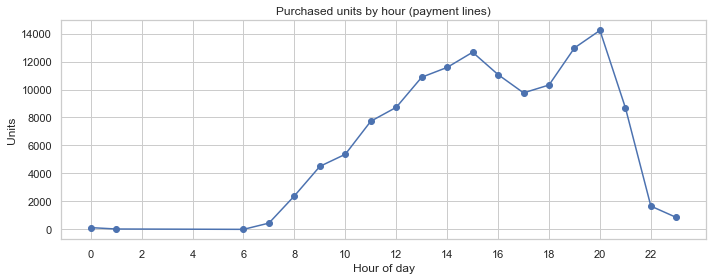

In [12]:
hourly_lines = sales_lines.copy()
hourly_lines["sale_hour"] = pd.to_datetime(hourly_lines["Time"].astype(str), format="%H:%M:%S", errors="coerce").dt.hour
hourly = hourly_lines.groupby("sale_hour").agg(units=("Qty", "sum"), gross_eur=("Gross Sales_eur", "sum"))
display(hourly.round(2))
fig, ax = plt.subplots(figsize=(10,4))
ax.plot(hourly.index, hourly["units"], marker="o")
ax.set(title="Purchased units by hour (payment lines)", xlabel="Hour of day", ylabel="Units")
ax.set_xticks(range(0,24,2)); plt.tight_layout(); plt.show()

Next, I compared sales across different days of the week and trading hours.

Weekend sales were noticeably higher than weekday sales, with average daily weekend revenue approximately 53.95% higher. The busiest trading hour was 8 PM.

These patterns could help the business decide when additional staff or product preparation may be needed.

### 3.5 Product category contribution


,payment_gross_eur,units,rows,revenue_share_pct
category_analysis,,,,
Gelato,144025.70,34370.0,26288,26.27
Coffee,98306.90,26970.0,23705,17.93
Special Tubs,89270.00,14305.0,12488,16.28
Waffles and Crepes,73925.20,11516.0,10241,13.48
Milkshakes,46051.70,7778.0,6440,8.40
Menu,16184.00,3577.0,3025,2.95
Uncategorised,16124.85,3217.0,2552,2.94
Grilled Sandwiches,12224.00,1814.0,1607,2.23
Toppings,10810.30,20128.0,11153,1.97


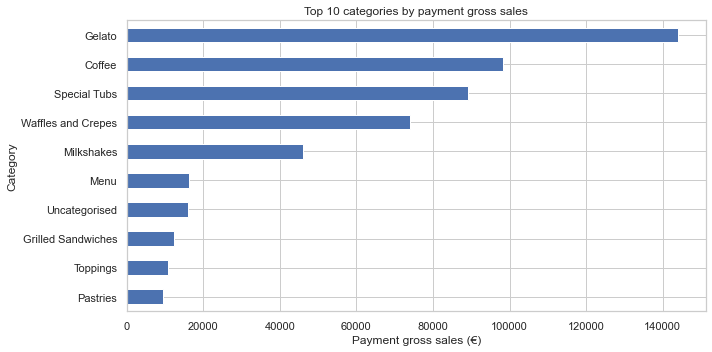

In [13]:
category_summary = (sales_lines.groupby("category_analysis", dropna=False)
    .agg(payment_gross_eur=("Gross Sales_eur", "sum"), units=("Qty", "sum"), rows=("Item", "size"))
    .sort_values("payment_gross_eur", ascending=False))
category_summary["revenue_share_pct"] = 100 * category_summary["payment_gross_eur"] / category_summary["payment_gross_eur"].sum()
display(category_summary.head(15).round(2))
fig, ax = plt.subplots(figsize=(10,5))
category_summary.head(10).sort_values("payment_gross_eur")["payment_gross_eur"].plot.barh(ax=ax)
ax.set(title="Top 10 categories by payment gross sales", xlabel="Payment gross sales (€)", ylabel="Category")
plt.tight_layout(); plt.show()

### Product and Category Performance

I also examined which products and categories generated the most revenue.

Gelato was the highest-revenue category, followed by Coffee and
Special Tubs. At the individual product level, Gelato and Vanilla
Milkshake were among the strongest performers.

Understanding these differences can help the business prioritise
popular products and review items with lower sales.

### 3.6 Best-selling products by revenue and units


In [14]:
products = (sales_lines.groupby("item_analysis", dropna=False)
    .agg(payment_gross_eur=("Gross Sales_eur", "sum"), units=("Qty", "sum"), rows=("Item", "size")))
print("Top 15 products by payment gross sales")
display(products.sort_values("payment_gross_eur", ascending=False).head(15).round(2))
print("Top 15 products by units")
display(products.sort_values("units", ascending=False).head(15).round(2))

Top 15 products by payment gross sales


,payment_gross_eur,units,rows
item_analysis,,,
Gelato,120501.8,25664.0,19202
Vanilla Milkshake,41544.0,7055.0,5790
Cappuccino,31327.2,8838.0,7543
Melted tub,17894.5,3293.0,2613
Bueno Buster Tub,15446.0,2397.0,2090
99 Cones,14944.6,5671.0,4558
Americano,13235.7,4062.0,3518
Strawberry & Nutella crepe,12675.0,1950.0,1664
Nutella Crepe,11377.5,1896.0,1624


Top 15 products by units


,payment_gross_eur,units,rows
item_analysis,,,
Gelato,120501.8,25664.0,19202
Topping,8905.5,17230.0,8778
Cappuccino,31327.2,8838.0,7543
Vanilla Milkshake,41544.0,7055.0,5790
99 Cones,14944.6,5671.0,4558
Americano,13235.7,4062.0,3518
Melted tub,17894.5,3293.0,2613
Bueno Buster Tub,15446.0,2397.0,2090
Latte,8066.4,2279.0,2027


### 3.7 Average order value (AOV) and caveats
- Daily AOV = payment gross revenue / distinct payment transaction IDs **on that day**.
- An overall AOV should be calculated from total payment gross revenue divided by the **overall unique transaction count**, rather than averaging daily AOVs. AOV does not include refunds here.

In [15]:
daily_sales["aov_payment_eur"] = np.where(daily_sales["transactions"] > 0,
    daily_sales["payment_gross_eur"] / daily_sales["transactions"], np.nan)
overall_aov = sales_lines["Gross Sales_eur"].sum() / sales_lines["Transaction ID"].nunique()
print("Overall payment AOV (€):", round(overall_aov, 2))
display(daily_sales["aov_payment_eur"].describe().round(2))
assert np.isclose(daily_sales["payment_gross_eur"].sum(), category_summary["payment_gross_eur"].sum())
print("Category totals reconcile with payment-only revenue.")

Overall payment AOV (€): 9.31


count    360.00
mean       9.14
std        0.98
min        6.94
25%        8.47
50%        9.07
75%        9.78
max       13.33
Name: aov_payment_eur, dtype: float64

Category totals reconcile with payment-only revenue.


### Key Takeaways

The exploratory analysis showed that Melt Gelato's sales follow
recognisable monthly, weekly and hourly patterns.

These findings provide a useful starting point for understanding
customer demand and identifying opportunities to improve stock
preparation and staff scheduling.

The next stage examines whether weather conditions are also
associated with changes in sales.

### Interpretation notes
- **Demand variability:** Across 360 observed days, mean refund-adjusted daily gross revenue was **€1,507.43** (SD **€612.09**, coefficient of variation **0.406**). This indicates substantial variation in daily demand; it does not by itself establish its cause.
- **Seasonality:** Payment-only monthly gross revenue was highest in **May 2025 (€61,930.60)** and lowest in **January 2025 (€28,197.40)**. May also had the highest payment revenue per observed day (**€1,997.76**). Month-level figures here are *payment-only* and should not be confused with refund-adjusted annual revenue.
- **Weekday pattern:** Mean payment-only daily revenue was highest on **Sunday (€2,118.29)**, followed by **Saturday (€1,860.80)**; Tuesday was lowest (**€1,175.37**). This supports further testing of weekend demand differences, not a causal claim.
- **Peak hour:** **20:00** had the highest payment-line quantity (**14,227 units**) and payment gross revenue (**€64,313.40**), aggregated over the year. This is not the number of customers simultaneously present.
- **Categories:** Gelato (**€144,025.70; 26.27%**), Coffee (**€98,306.90; 17.93%**), and Special Tubs (**€89,270.00; 16.28%**) led payment-only category revenue. **Uncategorised** still accounts for **€16,124.85**; this limits category-level precision.
- **Products:** The generic item **Gelato** led product revenue (**€120,501.80**), while **Topping** ranked highly in units but much lower in revenue. These rankings reflect POS item labels, not necessarily individual flavours or distinct SKUs.
- **Average order value:** Total payment-only gross revenue divided by distinct payment transaction IDs was **€9.31**. The mean of daily AOVs (**€9.14**) differs because it weights each day equally.

- Payment-only analysis excludes void-labelled lines and does not subtract refunds. Refund-adjusted annual gross revenue is **€542,676.35**. Duplicate occurrences were retained because their validity has not been independently established. Five calendar dates have no POS records and are not assumed to have zero sales.
